# Axial buckling of cylinders with integral blade stringers: Card and Jones (1966)

M. F. Card and R. M. Jones, *Experimental and theoretical results for buckling of eccentrically stiffened cylinders*, NASA TN D-3639, October 1966 (NTRS 19660027866).

Card and Jones tested in axial compression twelve longitudinally stiffened aluminium cylinders, in pairs with the stiffeners outside (external) or inside (internal) the skin. Cylinders 1 to 4 have integral rectangular (blade) stringers machined from 3/8 in plate, the configuration of this notebook; cylinders 5 to 12 have riveted Z stringers. For each cylinder their Table I gives the experimental buckling load and number of circumferential waves, and the buckling load of a smeared-stiffener theory for clamped and for simply supported ends (Galerkin solutions with a membrane pre-buckling state, Appendix A and Block, Card and Mikulas, NASA TN D-2960, 1965). The externally stiffened cylinders carried more than twice the load of the internally stiffened ones.

This notebook models cylinders 1 to 4 with `panels`, with the skin as curved panels between the stringers and each stringer as a flat plate strip, a `MultiDomain` assembly, and compares the linear buckling loads with the test and with the smeared theory. The same assembly is used for the vibration tests of Sewall and Naumann (1968) in `sewall1968_blade_cylinder_vibration.ipynb`, through the module `blade_cylinder_utils.py`.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import blade_cylinder_utils as bu
from blade_cylinder_utils import IN, LBF, PSI


def pct(value, ref):
    return 100*(value - ref)/ref


def markdown_table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    return Markdown('\n'.join(out))

## Test data

Table I (p. 7) of the report, cylinders 1 to 4, all of 2024-T351 aluminium alloy with $E = 10.5 \times 10^3$ ksi and $\mu = 0.32$ (footnote of Table I): skin thickness $t$, length $L$, radius of the middle surface $R$, area of the stiffened cross-section $A_t$ (by weighing, p. 5), experimental buckling load $\bar{P}_e$, average stress $\bar{\sigma}_e$, experimental number of circumferential waves $n_e$, and the buckling loads per unit length of circumference $\bar{N} = \bar{P}/(2\pi R)$ of the test ($\bar{N}_e$) and of the theory for clamped ($\bar{N}_c$) and simply supported ($\bar{N}_s$) ends.

The headers of the columns $\bar{N}$ of Table I read kips/in. and MN/m, but the values are in lb/in and kN/m: for cylinder 1, $112.6$ kips $/(2\pi \times 9.55$ in$) = 1877$ lb/in, the printed value, and $1877$ lb/in $= 328.7$ kN/m, printed 329 (derived). The values in lb/in are used below.

Fig. 2(b) (p. 6) gives the stringer: width 0.097 in (0.246 cm), height 0.33 in (0.84 cm), fillet radius 0.03 in (0.08 cm), spacing 1.00 in (2.54 cm); the number of stringers is not stated, $2\pi \times 9.55/1.00 = 60.0$ (derived), so 60.

In [2]:
E_KSI, NU = 10.5e3, 0.32
E = E_KSI*1e3*PSI
R_IN = 9.55
NSTIFF = 60
WIDTH, HEIGHT, FILLET = 0.097, 0.33, 0.03
# Card and Jones (1966), Table I(a) (p. 7): side, t in, L in, A_t in^2, P_e kips,
# sigma_e ksi, n_e, N_e, N_c, N_s lb/in (headed kips/in.)
TABLE_I = {
    1: ('external', 0.0283, 38.00, 3.69, 112.6, 30.5, 6, 1877, 2036, 1145),
    2: ('internal', 0.0277, 38.00, 3.72, 48.0, 12.9, 6, 800, 997, 687),
    3: ('external', 0.0275, 23.75, 3.70, 127.2, 34.4, 7, 2120, 2595, 1326),
    4: ('internal', 0.0280, 23.75, 3.63, 58.0, 16.0, 6, 965, 1226, 722),
}
# Table I(b), SI: P_e kN, N_e, N_c, N_s kN/m (headed MN/m)
TABLE_I_SI = {1: (500, 329, 357, 200), 2: (214, 140, 175, 120),
              3: (566, 371, 454, 232), 4: (258, 169, 215, 127)}
print('E = %.1f ksi = %.1f GPa (Table I(b): 72 400 MN/m^2)' % (E_KSI, E/1e9))
rows = []
for cyl, (side, t, L, At, Pe, se, ne, Ne, Nc, Ns) in TABLE_I.items():
    rows.append([cyl, side, t, L, At, Pe, ne, Ne, Nc, Ns,
                 '%.0f (%d)' % (Pe*1e3/(2*np.pi*R_IN), Ne),
                 '%.1f (%d)' % (Ne*LBF/IN/1e3, TABLE_I_SI[cyl][1])])
display(markdown_table(['cyl.', 'stringers', 't, in', 'L, in', 'A_t, in^2', 'P_e, kips', 'n_e',
                        'N_e', 'N_c', 'N_s', 'P_e/(2 pi R), lb/in (N_e)', 'N_e, kN/m (SI table)'], rows))

E = 10500.0 ksi = 72.4 GPa (Table I(b): 72 400 MN/m^2)


| cyl. | stringers | t, in | L, in | A_t, in^2 | P_e, kips | n_e | N_e | N_c | N_s | P_e/(2 pi R), lb/in (N_e) | N_e, kN/m (SI table) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | external | 0.0283 | 38.0 | 3.69 | 112.6 | 6 | 1877 | 2036 | 1145 | 1877 (1877) | 328.7 (329) |
| 2 | internal | 0.0277 | 38.0 | 3.72 | 48.0 | 6 | 800 | 997 | 687 | 800 (800) | 140.1 (140) |
| 3 | external | 0.0275 | 23.75 | 3.7 | 127.2 | 7 | 2120 | 2595 | 1326 | 2120 (2120) | 371.3 (371) |
| 4 | internal | 0.028 | 23.75 | 3.63 | 58.0 | 6 | 965 | 1226 | 722 | 967 (965) | 169.0 (169) |

**Datum of the stringer height.** The area $A_t$ of Table I checks the height of 0.33 in as measured from the skin surface: the skin, $2\pi R t$, plus 60 rectangles $0.097 \times 0.33$ in with two fillets each, $2 r_F^2 (1 - \pi/4)$, plus the four doubler plates of the two butt joints, $0.70 \times 0.020$ in each (p. 5), is within 2 % of $A_t$ (derived; the rivets are not counted). A height measured from the skin middle surface or including the skin would reduce the stringer area by 4 % or 8 % and the total by 2 % or 4 %.

In [3]:
rows = []
A_s = WIDTH*HEIGHT + 2*FILLET**2*(1 - np.pi/4)
for cyl, (side, t, L, At, *_) in TABLE_I.items():
    A = 2*np.pi*R_IN*t + NSTIFF*A_s + 4*0.70*0.020
    rows.append([cyl, '%.3f' % (2*np.pi*R_IN*t), '%.3f' % (NSTIFF*A_s), '%.3f' % A, At, '%+.1f%%' % pct(A, At)])
display(markdown_table(['cyl.', 'skin, in^2', 'stringers, in^2', 'total with doublers, in^2', 'A_t, in^2',
                        'difference'], rows))

| cyl. | skin, in^2 | stringers, in^2 | total with doublers, in^2 | A_t, in^2 | difference |
|---|---|---|---|---|---|
| 1 | 1.698 | 1.944 | 3.698 | 3.69 | +0.2% |
| 2 | 1.662 | 1.944 | 3.662 | 3.72 | -1.6% |
| 3 | 1.650 | 1.944 | 3.650 | 3.7 | -1.4% |
| 4 | 1.680 | 1.944 | 3.680 | 3.63 | +1.4% |

## Model

**Discrete stringers** (see `bu.build_cylinder`). The skin between two stringers is a curved panel of the Sanders-Koiter cylindrical shell model (`cylshell_clpt_sanders`) and each stringer a flat plate strip normal to the skin, of thickness $t_b = 0.097$ in and width $h_b = t/2 + 0.33$ in, from the middle surface of the skin to the stringer tip, connected to the skin with the base-flange connection `'BFycte'` (displacements and rotation about the stringer axis continuous) and the skin panels to each other with `'SSycte'`, both imposed exactly with `conn_method='null-space'` (Castro and Donadon 2017, https://doi.org/10.1016/j.compstruct.2016.10.026). The blade stands inside or outside the skin according to the edge of the blade that is connected; the eccentricity of the stringers, the distance $\bar{z}$ of their centroid from the middle surface of the skin in the smeared theory, follows from this geometry. The blade overlaps the skin over $t/2$, about the area of the two fillets, which the plate strips do not represent.

The stringers carry about half of the axial load, and the general instability of a stringer-stiffened cylinder bends them in their own plane, radially. The geometric stiffness of a plate model with the von Kármán strains contains the terms of the out-of-plane displacement only, $N_{xx} w_{,x}^2$, and would miss the destabilizing work of the stringer load $N_{xx} v_{,x}^2$ on the in-plane (radial) deflection of the blade; the blades are therefore modelled with `plate_clpt_gl`, whose Green-Lagrange membrane strains give the in-plane terms of the geometric stiffness too, with the same linear stiffness as `plate_clpt_donnell`.

**Symmetry.** The buckling mode of a cylinder with 60 identical, equally spaced stringers is close to $w \propto \cos n\theta$ times an axial shape; it is symmetric about two planes $\theta = 0$ and $\theta = \pi$ through the middle of a bay, and half of the cylinder, with $v = w_{,y} = 0$ on these planes, contains it for every $n$ (the half model is compared with the full cylinder in the notebook of Sewall and Naumann).

**Boundary conditions and pre-buckling state.** The test cylinders were potted at both ends in a low-temperature alloy, ground flat and parallel and loaded between the platens of a testing machine, with 1/4 in aluminium bulkheads held by the potting (p. 6). Four analyses are run:

| analysis | ends | pre-buckling state | function |
|---|---|---|---|
| clamped, linear | $u = v = w = w_{,x} = 0$ at $x = 0$; the same at $x = L$ with the uniform shortening $u = -\lambda\delta$ prescribed on skin and blades | linear static solution, with the bending of the skin near the ends | `bu.buckling_clamped` |
| SS, linear | $N_x = v = w = M_x = 0$ at both ends, equal and opposite end loads $E t \varepsilon$ (skin) and $E t_b \varepsilon$ (blades); one point $u = 0$ against the rigid translation | linear static solution | `bu.buckling_ss` |
| clamped, membrane | $u = v = w = w_{,x} = 0$ at both ends | membrane, $N_{xx} = -E t \varepsilon$ in the skin, $-E t_b \varepsilon$ in the blades | `bu.buckling_membrane` |
| SS, membrane | as SS, linear | membrane | `bu.buckling_membrane` |

The clamped and simply supported conditions are those of Card and Jones (p. 9 and 10), whose theory uses the membrane pre-buckling state; the clamped analysis with the linear pre-buckling state is closest to the test. The critical load $\bar{P}$ is $\lambda$ times the axial force of the reference state (for the prescribed shortening, the resultant of the reactions at $x = L$, `MultiDomain.reaction_resultant`), and $\bar{N} = \bar{P}/(2\pi R)$.

## Convergence

The number of Ritz terms is increased in four steps: $m_x$ along $x$ (skin and blades), $n_y$ across a full skin bay, $n_b$ across a blade. The table gives the critical $\bar{N}$ of each analysis and its change from the previous step; the last step is used in the comparisons.

In [4]:
LEVELS = [(10, 4, 4), (14, 6, 4), (18, 8, 5), (22, 10, 6)]
ANALYSES = {
    'clamped, linear': lambda *a: bu.buckling_clamped(*a),
    'SS, linear': lambda *a: bu.buckling_ss(*a),
    'clamped, membrane': lambda *a: bu.buckling_membrane(*a[:8], 'CC', *a[8:]),
    'SS, membrane': lambda *a: bu.buckling_membrane(*a[:8], 'SS', *a[8:]),
}
RES = {}
rows = []
for cyl, (side, t, L, *_) in TABLE_I.items():
    args = (R_IN*IN, t*IN, L*IN, E, NU, WIDTH*IN, (t/2 + HEIGHT)*IN, side)
    for name, func in ANALYSES.items():
        prev = None
        for i, (mx, ny, nyb) in enumerate(LEVELS):
            P, modes, md, skin, dt = func(*args, mx, ny, nyb)
            N = P/LBF/(2*np.pi*R_IN)
            RES[(cyl, name, i)] = (N, modes[0][1], modes[0][2], md if i == len(LEVELS) - 1 else None,
                                   skin, modes[0][3],
                                   [(lam/modes[0][0]*N, m, n) for lam, m, n, c in modes[:5]])
            rows.append([cyl, name, '%d, %d, %d' % (mx, ny, nyb), md.get_size(), '%.1f' % dt,
                         '%.0f' % N, '(%d, %d)' % modes[0][1:3],
                         '-' if prev is None else '%+.2f%%' % pct(N, prev)])
            prev = N
display(markdown_table(['cyl.', 'analysis', 'm_x, n_y, n_b', 'dofs', 'time, s', 'N, lb/in', '(m, n)',
                        'change'], rows))
FINAL = len(LEVELS) - 1

| cyl. | analysis | m_x, n_y, n_b | dofs | time, s | N, lb/in | (m, n) | change |
|---|---|---|---|---|---|---|---|
| 1 | clamped, linear | 10, 4, 4 | 7320 | 3.5 | 2039 | (2, 9) | - |
| 1 | clamped, linear | 14, 6, 4 | 12684 | 6.8 | 2205 | (1, 7) | +8.14% |
| 1 | clamped, linear | 18, 8, 5 | 21060 | 20.2 | 2216 | (1, 7) | +0.50% |
| 1 | clamped, linear | 22, 10, 6 | 31680 | 43.8 | 2219 | (1, 7) | +0.14% |
| 1 | SS, linear | 10, 4, 4 | 7320 | 3.0 | 1224 | (1, 6) | - |
| 1 | SS, linear | 14, 6, 4 | 12684 | 6.4 | 1227 | (1, 6) | +0.25% |
| 1 | SS, linear | 18, 8, 5 | 21060 | 17.7 | 1228 | (1, 6) | +0.09% |
| 1 | SS, linear | 22, 10, 6 | 31680 | 38.7 | 1228 | (1, 6) | -0.00% |
| 1 | clamped, membrane | 10, 4, 4 | 7320 | 2.1 | 2226 | (1, 7) | - |
| 1 | clamped, membrane | 14, 6, 4 | 12684 | 3.5 | 2219 | (1, 7) | -0.32% |
| 1 | clamped, membrane | 18, 8, 5 | 21060 | 7.6 | 2217 | (1, 7) | -0.09% |
| 1 | clamped, membrane | 22, 10, 6 | 31680 | 12.8 | 2216 | (1, 7) | -0.04% |
| 1 | SS, membrane | 10, 4, 4 | 7320 | 2.3 | 1215 | (1, 6) | - |
| 1 | SS, membrane | 14, 6, 4 | 12684 | 4.3 | 1213 | (1, 6) | -0.17% |
| 1 | SS, membrane | 18, 8, 5 | 21060 | 9.1 | 1211 | (1, 6) | -0.12% |
| 1 | SS, membrane | 22, 10, 6 | 31680 | 16.6 | 1210 | (1, 6) | -0.09% |
| 2 | clamped, linear | 10, 4, 4 | 7320 | 3.3 | 928 | (2, 8) | - |
| 2 | clamped, linear | 14, 6, 4 | 12684 | 6.4 | 1049 | (1, 6) | +13.03% |
| 2 | clamped, linear | 18, 8, 5 | 21060 | 19.9 | 1050 | (1, 6) | +0.09% |
| 2 | clamped, linear | 22, 10, 6 | 31680 | 41.5 | 1050 | (1, 6) | +0.01% |
| 2 | SS, linear | 10, 4, 4 | 7320 | 3.1 | 671 | (1, 5) | - |
| 2 | SS, linear | 14, 6, 4 | 12684 | 6.0 | 673 | (1, 5) | +0.31% |
| 2 | SS, linear | 18, 8, 5 | 21060 | 16.1 | 673 | (1, 5) | +0.06% |
| 2 | SS, linear | 22, 10, 6 | 31680 | 38.9 | 673 | (1, 5) | -0.01% |
| 2 | clamped, membrane | 10, 4, 4 | 7320 | 2.1 | 1051 | (2, 7) | - |
| 2 | clamped, membrane | 14, 6, 4 | 12684 | 3.3 | 1048 | (2, 7) | -0.29% |
| 2 | clamped, membrane | 18, 8, 5 | 21060 | 6.9 | 1047 | (2, 7) | -0.08% |
| 2 | clamped, membrane | 22, 10, 6 | 31680 | 12.2 | 1047 | (2, 7) | -0.04% |
| 2 | SS, membrane | 10, 4, 4 | 7320 | 2.3 | 671 | (1, 5) | - |
| 2 | SS, membrane | 14, 6, 4 | 12684 | 4.2 | 670 | (1, 5) | -0.15% |
| 2 | SS, membrane | 18, 8, 5 | 21060 | 9.7 | 669 | (1, 5) | -0.11% |
| 2 | SS, membrane | 22, 10, 6 | 31680 | 17.8 | 669 | (1, 5) | -0.08% |
| 3 | clamped, linear | 10, 4, 4 | 7320 | 3.5 | 2952 | (1, 8) | - |
| 3 | clamped, linear | 14, 6, 4 | 12684 | 6.7 | 2956 | (1, 8) | +0.13% |
| 3 | clamped, linear | 18, 8, 5 | 21060 | 21.3 | 2959 | (1, 8) | +0.11% |
| 3 | clamped, linear | 22, 10, 6 | 31680 | 86.6 | 2959 | (1, 8) | -0.02% |
| 3 | SS, linear | 10, 4, 4 | 7320 | 3.1 | 1508 | (1, 7) | - |
| 3 | SS, linear | 14, 6, 4 | 12684 | 6.3 | 1507 | (1, 7) | -0.05% |
| 3 | SS, linear | 18, 8, 5 | 21060 | 15.9 | 1507 | (1, 7) | -0.03% |
| 3 | SS, linear | 22, 10, 6 | 31680 | 44.1 | 1506 | (1, 7) | -0.06% |
| 3 | clamped, membrane | 10, 4, 4 | 7320 | 2.3 | 2905 | (1, 8) | - |
| 3 | clamped, membrane | 14, 6, 4 | 12684 | 3.7 | 2891 | (1, 8) | -0.47% |
| 3 | clamped, membrane | 18, 8, 5 | 21060 | 8.2 | 2887 | (1, 8) | -0.14% |
| 3 | clamped, membrane | 22, 10, 6 | 31680 | 15.0 | 2885 | (1, 8) | -0.07% |
| 3 | SS, membrane | 10, 4, 4 | 7320 | 2.5 | 1468 | (1, 7) | - |
| 3 | SS, membrane | 14, 6, 4 | 12684 | 4.5 | 1464 | (1, 7) | -0.31% |
| 3 | SS, membrane | 18, 8, 5 | 21060 | 9.0 | 1461 | (1, 7) | -0.19% |
| 3 | SS, membrane | 22, 10, 6 | 31680 | 17.8 | 1459 | (1, 7) | -0.13% |
| 4 | clamped, linear | 10, 4, 4 | 7320 | 3.4 | 1314 | (1, 7) | - |
| 4 | clamped, linear | 14, 6, 4 | 12684 | 6.6 | 1303 | (1, 7) | -0.83% |
| 4 | clamped, linear | 18, 8, 5 | 21060 | 19.5 | 1302 | (1, 7) | -0.06% |
| 4 | clamped, linear | 22, 10, 6 | 31680 | 44.9 | 1302 | (1, 7) | -0.03% |
| 4 | SS, linear | 10, 4, 4 | 7320 | 3.0 | 738 | (1, 6) | - |
| 4 | SS, linear | 14, 6, 4 | 12684 | 6.4 | 738 | (1, 6) | -0.02% |
| 4 | SS, linear | 18, 8, 5 | 21060 | 17.2 | 737 | (1, 6) | -0.08% |
| 4 | SS, linear | 22, 10, 6 | 31680 | 40.8 | 737 | (1, 6) | -0.08% |
| 4 | clamped, membrane | 10, 4, 4 | 7320 | 2.1 | 1292 | (1, 7) | - |
| 4 | clamped, membrane | 14, 6, 4 | 12684 | 3.3 | 1288 | (1, 7) | -0.34% |
| 4 | clamped, membrane | 18, 8, 5 | 21060 | 7.5 | 1286 | (1, 7) | -0.09% |
| 4 | clamped, membrane | 22, 10, 6 | 31680 | 13.0 | 1286 | (1, 7) | -0.04% |
| 4 | SS, membrane | 10, 4, 4 | 7320 | 2.4 | 730 | (1, 6) | - |
| 4 | SS, membrane | 14, 6, 4 | 12684 | 4.4 | 728 | (1, 6) | -0.37% |
| 4 | SS, membrane | 18, 8, 5 | 21060 | 9.2 | 726 | (1, 6) | -0.23% |
| 4 | SS, membrane | 22, 10, 6 | 31680 | 20.6 | 725 | (1, 6) | -0.15% |

## Comparison with the test and with the smeared theory

$\bar{N}$ in lb/in, the wave numbers $(m, n)$ of the critical mode ($m$ axial half-waves, `bu.classify`), and the relative differences: the clamped analyses against the experimental $\bar{N}_e$ and the clamped theory $\bar{N}_c$, the simply supported ones against $\bar{N}_s$.

In [5]:
rows = []
for cyl, (side, t, L, At, Pe, se, ne, Ne, Nc, Ns) in TABLE_I.items():
    r = {name: RES[(cyl, name, FINAL)] for name in ANALYSES}
    cl, cm, sl, sm = (r['clamped, linear'], r['clamped, membrane'], r['SS, linear'], r['SS, membrane'])
    rows.append([cyl, side, '%d (n = %d)' % (Ne, ne),
                 '%.0f (%d, %d)' % cl[:3], '%+.1f%%' % pct(cl[0], Ne), '%+.1f%%' % pct(cl[0], Nc),
                 Nc, '%.0f (%d, %d)' % cm[:3], '%+.1f%%' % pct(cm[0], Nc),
                 Ns, '%.0f (%d, %d)' % sl[:3], '%+.1f%%' % pct(sl[0], Ns),
                 '%.0f (%d, %d)' % sm[:3], '%+.1f%%' % pct(sm[0], Ns)])
display(markdown_table(['cyl.', 'stringers', 'test N_e', 'clamped, linear', 'vs N_e', 'vs N_c',
                        'N_c (theory)', 'clamped, membrane', 'vs N_c', 'N_s (theory)', 'SS, linear', 'vs N_s',
                        'SS, membrane', 'vs N_s'], rows))

| cyl. | stringers | test N_e | clamped, linear | vs N_e | vs N_c | N_c (theory) | clamped, membrane | vs N_c | N_s (theory) | SS, linear | vs N_s | SS, membrane | vs N_s |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | external | 1877 (n = 6) | 2219 (1, 7) | +18.2% | +9.0% | 2036 | 2216 (1, 7) | +8.8% | 1145 | 1228 (1, 6) | +7.3% | 1210 (1, 6) | +5.7% |
| 2 | internal | 800 (n = 6) | 1050 (1, 6) | +31.3% | +5.3% | 997 | 1047 (2, 7) | +5.0% | 687 | 673 (1, 5) | -2.0% | 669 (1, 5) | -2.7% |
| 3 | external | 2120 (n = 7) | 2959 (1, 8) | +39.6% | +14.0% | 2595 | 2885 (1, 8) | +11.2% | 1326 | 1506 (1, 7) | +13.6% | 1459 (1, 7) | +10.0% |
| 4 | internal | 965 (n = 6) | 1302 (1, 7) | +34.9% | +6.2% | 1226 | 1286 (1, 7) | +4.9% | 722 | 737 (1, 6) | +2.0% | 725 (1, 6) | +0.4% |

**Test against theory.** Card and Jones found the experimental loads between 70 and 95 % of their clamped theory (p. 11). The ratios of the test to the clamped analyses of `panels`, and the ratio of the external to the internal cylinder of the same length:

In [6]:
rows = []
for cyl, (side, t, L, At, Pe, se, ne, Ne, Nc, Ns) in TABLE_I.items():
    rows.append([cyl, side, '%.2f' % (Ne/Nc), '%.2f' % (Ne/RES[(cyl, 'clamped, linear', FINAL)][0]),
                 '%.2f' % (Ne/RES[(cyl, 'clamped, membrane', FINAL)][0])])
display(markdown_table(['cyl.', 'stringers', 'N_e/N_c', 'N_e/panels clamped, linear',
                        'N_e/panels clamped, membrane'], rows))
rows = []
for ext, inn in ((1, 2), (3, 4)):
    rows.append(['%d/%d' % (ext, inn), '%.2f' % (TABLE_I[ext][7]/TABLE_I[inn][7]),
                 '%.2f' % (TABLE_I[ext][8]/TABLE_I[inn][8]),
                 '%.2f' % (RES[(ext, 'clamped, linear', FINAL)][0]/RES[(inn, 'clamped, linear', FINAL)][0])])
display(markdown_table(['cylinders', 'test', 'clamped theory', 'panels clamped, linear'], rows))

| cyl. | stringers | N_e/N_c | N_e/panels clamped, linear | N_e/panels clamped, membrane |
|---|---|---|---|---|
| 1 | external | 0.92 | 0.85 | 0.85 |
| 2 | internal | 0.80 | 0.76 | 0.76 |
| 3 | external | 0.82 | 0.72 | 0.73 |
| 4 | internal | 0.79 | 0.74 | 0.75 |

| cylinders | test | clamped theory | panels clamped, linear |
|---|---|---|---|
| 1/2 | 2.35 | 2.04 | 2.11 |
| 3/4 | 2.20 | 2.12 | 2.27 |

**Neighbouring modes.** The five lowest buckling loads $\bar{N}$ (lb/in) of the analyses with the linear pre-buckling state, with their $(m, n)$:

In [7]:
rows = []
for cyl in TABLE_I:
    for name in ('clamped, linear', 'SS, linear'):
        rows.append([cyl, name] + ['%.0f (%d, %d)' % mode for mode in RES[(cyl, name, FINAL)][6]])
display(markdown_table(['cyl.', 'analysis', '1', '2', '3', '4', '5'], rows))

| cyl. | analysis | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|
| 1 | clamped, linear | 2219 (1, 7) | 2363 (1, 8) | 2370 (1, 6) | 2482 (2, 8) | 2483 (2, 9) |
| 1 | SS, linear | 1228 (1, 6) | 1272 (1, 5) | 1548 (1, 7) | 1782 (2, 8) | 1832 (2, 7) |
| 2 | clamped, linear | 1050 (1, 6) | 1052 (2, 7) | 1077 (2, 8) | 1082 (1, 7) | 1191 (3, 8) |
| 2 | SS, linear | 673 (1, 5) | 761 (1, 6) | 775 (2, 7) | 850 (2, 6) | 897 (2, 8) |
| 3 | clamped, linear | 2959 (1, 8) | 2984 (1, 9) | 3155 (1, 7) | 3173 (1, 10) | 3471 (1, 11) |
| 3 | SS, linear | 1506 (1, 7) | 1616 (1, 8) | 1651 (1, 6) | 1933 (1, 9) | 2203 (1, 5) |
| 4 | clamped, linear | 1302 (1, 7) | 1351 (1, 8) | 1534 (1, 6) | 1572 (1, 9) | 1656 (2, 8) |
| 4 | SS, linear | 737 (1, 6) | 787 (1, 7) | 1010 (1, 5) | 1035 (1, 8) | 1059 (2, 8) |

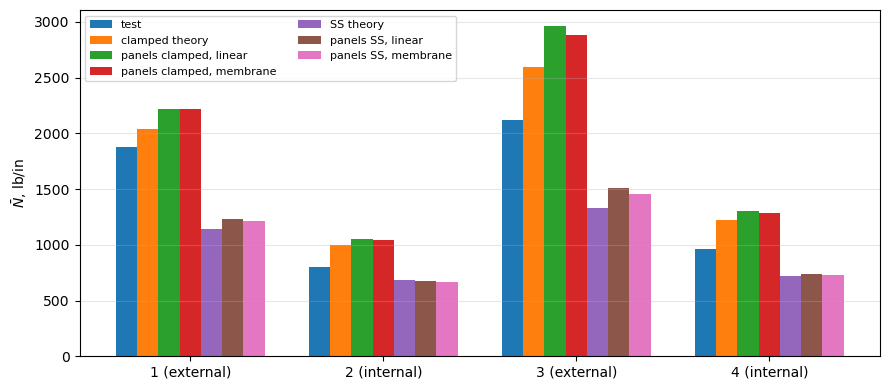

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
names = ['test', 'clamped theory', 'panels clamped, linear', 'panels clamped, membrane',
         'SS theory', 'panels SS, linear', 'panels SS, membrane']
width = 0.11
for k, name in enumerate(names):
    vals = []
    for cyl, row in TABLE_I.items():
        if name == 'test':
            vals.append(row[7])
        elif name == 'clamped theory':
            vals.append(row[8])
        elif name == 'SS theory':
            vals.append(row[9])
        else:
            vals.append(RES[(cyl, name[7:], FINAL)][0])
    ax.bar(np.arange(1, 5) + (k - 3)*width, vals, width, label=name)
ax.set_xticks(range(1, 5))
ax.set_xticklabels(['%d (%s)' % (cyl, row[0]) for cyl, row in TABLE_I.items()])
ax.set_ylabel(r'$\bar{N}$, lb/in')
ax.legend(fontsize=8, ncol=2)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Buckling modes

Normal displacement $w$ of the skin of the half cylinder, unrolled, for the critical mode of the clamped analysis with the linear pre-buckling state; the dots mark the stringers.

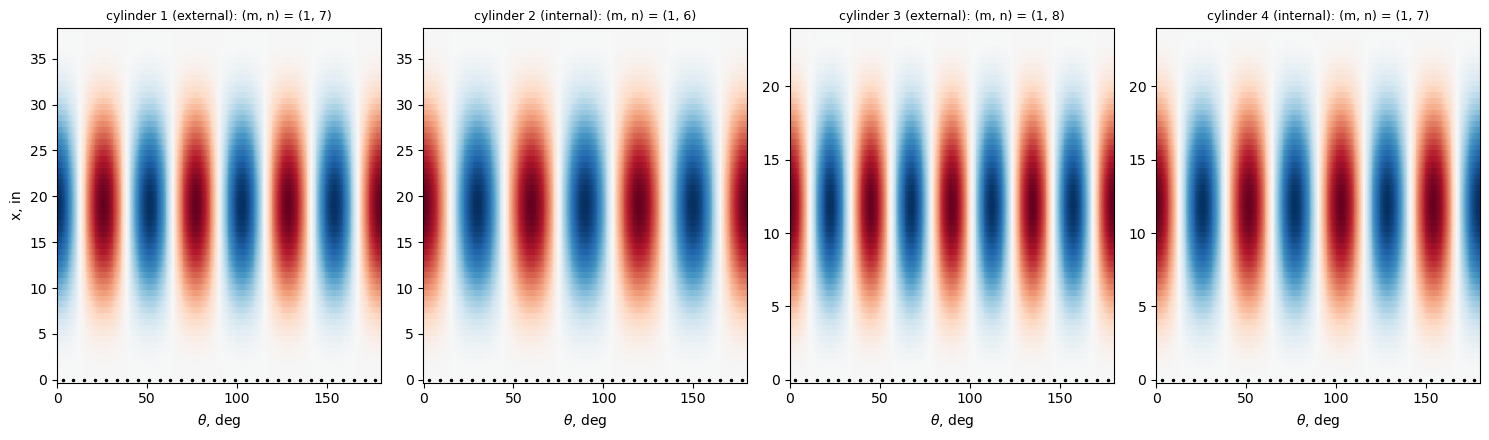

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
for ax, (cyl, row) in zip(axes, TABLE_I.items()):
    N, m, n, md, skin, c, _ = RES[(cyl, 'clamped, linear', FINAL)]
    x, th, w = bu.skin_w(md, c, skin, R_IN*IN)
    ax.pcolormesh(np.degrees(th), x/IN, (w/np.abs(w).max()).T, cmap='RdBu_r', shading='auto', vmin=-1, vmax=1)
    ax.plot(np.degrees((np.arange(NSTIFF//2) + 0.5)*2*np.pi/NSTIFF), np.zeros(NSTIFF//2), 'k.', ms=3)
    ax.set_title('cylinder %d (%s): (m, n) = (%d, %d)' % (cyl, row[0], m, n), fontsize=9)
    ax.set_xlabel(r'$\theta$, deg')
axes[0].set_ylabel('x, in')
plt.tight_layout()
plt.show()

## Discussion

- **Convergence.** With the last two numbers of terms the critical loads change by less than 0.2 %. The coarsest model of the long cylinders 1 and 2 ($L/R = 4$) has too few axial terms for the mode $m = 1$, $n = 6$ or 7 and finds a mode with $m = 2$ instead.
- **Smeared theory.** With the assumptions of Card and Jones (membrane pre-buckling state, clamped or simply supported ends), `panels` is within 5 % of their theory for the internally stiffened cylinders 2 and 4, and 6 % to 11 % above it for the externally stiffened cylinders 1 and 3. The two models differ in the stringers: in `panels` each stringer is a discrete plate strip connected along a line, with its own bending, twisting and in-plane bending, whereas the theory spreads the stringer stiffness over the circumference (smeared beams with the eccentricity $\bar{z}$ and the torsional stiffness $G_s J_s$, which Card and Jones found to raise the buckling load of these integral cylinders by 10 % to 20 %, p. 11). The blade of the model also overlaps the skin over $t/2$: its area is $0.097 \times 0.344 = 0.0334$ in$^2$ against $0.0324$ in$^2$ with the fillets (derived), 3 % more, with a slightly larger eccentricity for the external stringers. The differences are larger for the external stringers, for which the eccentricity raises the load most.
- **Pre-buckling state.** The linear static pre-buckling state, with the bending of the skin near the restrained ends, changes the critical load by 0.1 % to 3.2 % from the membrane state, most for cylinder 3, in line with the conclusion of Card and Jones that a membrane pre-buckling state is sufficient for assessing the eccentricity effect (p. 11).
- **Boundary conditions.** The clamped loads are 1.6 to 2.0 times the simply supported ones. The test loads lie between the two and 19 % to 53 % above the simply supported analysis of `panels` although imperfections can only lower them, which is why Card and Jones concluded that the test cylinders were more nearly clamped than simply supported (p. 11). The axial restraint of the clamped ends, with $u$ prescribed on the whole end section, contributes to the difference between the two conditions (Appendix B of the report).
- **Test against analysis.** The test loads are 72 % to 85 % of the clamped analysis of `panels`, against 79 % to 92 % of the clamped theory of the report (Card and Jones give 70 % to 95 % for all twelve cylinders). Linear buckling of the perfect cylinder is an upper bound: the test loads are reduced by the initial imperfections, to which axially compressed cylinders are sensitive (the external cylinders buckled with a loud report and large diamond-shaped buckles, p. 8), by the two butt joints per cylinder with riveted doubler plates (p. 5), by the potting of the ends in a soft alloy, which is not a perfect clamp, and by the scatter of the skin thickness ($\pm 8$ % of the average, p. 5).
- **External against internal stringers.** The ratio of the external to the internal cylinder of the same length is 2.11 and 2.27 in `panels`, 2.04 and 2.12 in the clamped theory, and 2.35 and 2.20 in the tests: the discrete model reproduces the eccentricity effect that motivated the tests.
- **Wave numbers.** The clamped analysis gives one more circumferential wave than the tests for cylinders 1, 3 and 4 ($n = 7$, 8, 7 against 6, 7, 6), with the measured $n$ the second or third lowest mode, 7 % (cylinders 1 and 3) and 18 % (cylinder 4) above the critical load (table above); the simply supported analysis gives the measured $n$ for cylinders 1, 3 and 4. Imperfections and the actual end restraint can select a neighbouring mode. Cylinder 1 developed two tiers of buckles in the test (p. 8); in `panels` its lowest mode with two axial half-waves, $(m, n) = (2, 8)$, is 12 % above the critical one.